# Week 4 — AI-Powered Customer Experience: LLMs as business components

Last week we judged a churn model by **profit**, not accuracy.

Today: first, a model that looks *too* good; then we will use a large language model (LLM) to read customer emails and turn them into data we can count, route and price.

| Part | Topic |
|---|---|
| A | Too good to be true: leakage in the churn model |
| B | Set up a free Gemini API key; first call |
| C | A simple baseline: keyword rules |
| D | The LLM reads the emails: prompt v1 vs. prompt v2 |
| E | Tokens, cost, and what the routing is worth in € |
| F | A chatbot with and without the company policy |

Everything is counting, percentages and the expected-value idea from week 3.

In [1]:
# These are all packages we have seen (You must be familiar by)
import json, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

In [2]:
# Set a bunchof parameters for plots
plt.rcParams.update({"figure.figsize": (7, 4),
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True,
                     "grid.alpha": 0.3})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#7a7a7a"

# Part A — Too good to be true: leakage

Same Telco data and same model as week 3. Load and clean it exactly as before.

In [3]:
LOCAL = Path("telco_churn.csv")
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# These are procedures we did before
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["churned"] = (df["Churn"] == "Yes").astype(int)
print(df.shape, "| base churn rate:", round(df["churned"].mean(), 3))

(7043, 22) | base churn rate: 0.265


## A1. A colleague's "better" model

A colleague adds one column from the call-centre system: **`calls_to_cancellation_line`**, the number of calls each customer made to the cancellations line in the last 30 days. Remeber, this column represents customers who call the cancellations line **AFTER** they have decided to leave

**Note:** The real Telco file does not have this column, so we simulate it: churners called it much more often.

There are three moments in this story:

1. Decision day. We pick whom to call with a retention offer.
2. The customer decides to leave and calls the cancellations line.
3. Churn is recorded in the data.

When we build the model, we use old customers whose whole story is finished, so the table has their calls next to their churn label. The column is genuinely in the training data, and the model learns “calls = churn”.

In [5]:
# Set a random seed so we all get the same values
rng = np.random.default_rng(4)
# churners call the cancellations line about 1.6 times on average, stayers almost never
df["calls_to_cancellation_line"] = rng.poisson(np.where(df["churned"] == 1, 1.6, 0.08))

# Get a summary of the share of customers who called at least once, for churners and stayers
df.groupby("Churn")["calls_to_cancellation_line"].apply(lambda s: (s > 0).mean()).round(2)

,calls_to_cancellation_line
Churn,
No,0.08
Yes,0.80


This table means that 80% of churners called the cancellations line, against 8% of stayers. The model will find this pattern immediately.

Now train the week 3 model twice: **without** and **with** the new column, and compare the AUCs (remember: 0.5 = guessing, 1 = perfect ranking).

In [6]:
# Convert the response to a vector of 1s and zeros
y = df["churned"].to_numpy()

# Write a function, programming is about automating: Make this function more flexible
def train_and_score(drop_cols):
    """
    This function does basically the same things as last week
    First create dummies,
    Split the dataset into 70/30 train test,
    Standardize,
    Run Logistic regression
    """
    X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "churned"] + drop_cols),
                       drop_first=True).astype(float)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

    model.fit(X_train, y_train)

    # Here i want probabilities, not 1/0 (we discussed this before)
    p = model.predict_proba(X_test)[:, 1]

    return model, X_test, y_test, p

# Drops calls_to_cancellation_line
honest_model, X_test_h, y_test, p_honest = train_and_score(["calls_to_cancellation_line"])

# Keeps calls_to_cancellation_line
leaky_model,  X_test_l, _, p_leaky  = train_and_score([])

print(f"Week 3 model (honest): AUC {roc_auc_score(y_test, p_honest):.2f}")
print(f"Colleague's model:     AUC {roc_auc_score(y_test, p_leaky):.2f}")

Week 3 model (honest): AUC 0.84
Colleague's model:     AUC 0.96


## The time test
The retention team wants to use the model to decide **whom to call before they leave**.

This is a clear case of leakage: On the day we decide whom to call, would we already know `calls_to_cancellation_line`? Why or why not?

Customers call the cancellations line AFTER they have decided to leave. On the day we choose whom to call, the customers we could still save have not called yet, so the column is 0 for them. The model "predicts" churn from the act of churning.


We can also see the weights as we did before. What is going on here?

In [7]:
weights = pd.Series(leaky_model[-1].coef_[0], index=X_test_l.columns)
weights.abs().sort_values(ascending=False).head(5).round(2)

,0
calls_to_cancellation_line,2.84
tenure,1.16
Contract_Two year,0.50
TotalCharges,0.39
InternetService_Fiber optic,0.38


In [8]:
weights2 = pd.Series(honest_model[-1].coef_[0], index=X_test_h.columns)
weights2.abs().sort_values(ascending=False).head(5).round(2)

,0
tenure,1.32
MonthlyCharges,0.71
TotalCharges,0.64
InternetService_Fiber optic,0.63
Contract_Two year,0.57


## A2. What happens on decision day?

On the day we choose whom to call, our customers **have not called the cancellations line yet**, so the column is 0 for everyone.
Let's give the colleague's model the test customers as they look on that day.

In [10]:
X_decision_day = X_test_l.copy()
X_decision_day["calls_to_cancellation_line"] = 0

p_day = leaky_model.predict_proba(X_decision_day)[:, 1]
flagged = int((p_day >= 0.5).sum())
print(f"Customers flagged as churners (p >= 0.5): {flagged} out of {len(p_day):,}")
print(f"Real churners among them in the test set: {int(y_test.sum()):,}")

Customers flagged as churners (p >= 0.5): 1 out of 2,113
Real churners among them in the test set: 561


> **The "better" model flags almost nobody.** It learned that "churn = calls the cancellations line". On decision day nobody has called yet, so it sees no churners.
> It looked great in testing because the test set came from the **same leaky table**. A result much better than your baseline should make you suspicious, not happy.

# Part B — Set up the LLM (Google Gemini, free tier)

1. Go to **https://aistudio.google.com**, sign in with a Google account, click **Get API key → Create API key**, and copy it.
2. In Colab, click the **key icon** (Secrets) in the left bar → **Add new secret**. Name: `GOOGLE_API_KEY`, value: your key. Switch on **Notebook access**.
3. Run the cells below.

> **Never paste a key into the notebook itself.** Anyone you share the notebook with could use it.
>
> **Privacy:** on the free tier, Google says it may use what you send to improve its products. That is why we use **invented** emails today. Never send real customer data to a free AI tool.

In [11]:
# The Google Gen AI library (already installed on most Colab machines; this makes sure)
# !pip -q install -U google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [14]:
from google import genai
from google.genai import types

try:
    from google.colab import userdata
    API_KEY = userdata.get("GOOGLE_API_KEY")
except Exception:
    import os
    API_KEY = os.environ.get("GOOGLE_API_KEY")

client = genai.Client(api_key=API_KEY)

# A small, cheap, fast model. If Google retires it, run the next cell and pick another "flash-lite" model.
MODEL = "gemini-3.5-flash-lite"

In [ ]:
# Optional: list the models your key can use (run only if MODEL gives an error)
# for m in client.models.list():
#     if "flash" in m.name:
#         print(m.name)

### The one function we use all day

`ask_llm(prompt)` sends text to the model and returns its answer.
It also **counts the tokens** of every call, sets **temperature 0** (as consistent as possible) and waits and retries if the free tier says "too many requests".
You don't need to understand every line, only what goes in and what comes out is important at this moment. For more explore on your own, these models are really cool!!!

In [15]:
# one row per call: tokens in, tokens out
TOKEN_LOG = []

def ask_llm(prompt, want_json=True, retries=3):
    config = types.GenerateContentConfig(
        temperature=0,
        response_mime_type="application/json" if want_json else "text/plain",
    )
    for attempt in range(retries):
        try:
            response = client.models.generate_content(model=MODEL, contents=prompt, config=config)
            u = response.usage_metadata
            TOKEN_LOG.append({"tokens_in": u.prompt_token_count or 0,
                              "tokens_out": (u.candidates_token_count or 0)
                                            + (getattr(u, "thoughts_token_count", 0) or 0)})
            return response.text
        except Exception as e:
            if attempt == retries - 1:
                raise
            print("Waiting 20 s and trying again:", str(e)[:80])
            time.sleep(20)

In [16]:
# First call: does it work?
print(ask_llm("In one sentence, what does a telecom retention team do?", want_json=False))

A telecom retention team works to prevent existing customers from canceling their services by offering targeted discounts, upgraded plans, and solutions to address their complaints.


## The data: 30 MegaTelCo customer emails

Invented emails, each **labelled by a person** (the "true answer"), the same way `Churn` was the true answer in week 3:

- `topic`: billing, network, contract, technical, other
- `sentiment`: negative, neutral, positive
- `churn_risk`: **high** if the customer says or clearly hints they will leave, switch, cancel or not renew; otherwise **low**

Three emails are in Albanian, as real MegaTelCo customers would write. You'd think Gemini would handle them like a pro!

In [17]:
EMAILS = [
    ("Third month in a row my bill is higher than my contract price. If this is not fixed by Friday I am moving to another operator.", "billing", "negative", "high"),
    ("Hi, could you tell me when my contract ends? I'd like to plan ahead.", "contract", "neutral", "low"),
    ("Internet at home has been dropping every evening for a week. I work from home, please fix this.", "network", "negative", "low"),
    ("Just wanted to say the technician who came on Tuesday was excellent. Problem solved in ten minutes.", "technical", "positive", "low"),
    ("Your competitor offers 100 GB for half of what I pay you. Give me a reason to stay.", "contract", "negative", "high"),
    ("I was charged twice for the same top-up on 3 March. Please refund one of them.", "billing", "negative", "low"),
    ("How do I set up voicemail on my new phone?", "technical", "neutral", "low"),
    ("No signal at all in Durrës city centre since yesterday. Is there an outage?", "network", "negative", "low"),
    ("I want to cancel my TV package. I never watch it.", "contract", "neutral", "high"),
    ("Great job on the new app, paying my bill takes seconds now.", "billing", "positive", "low"),
    ("Oh fantastic, another price increase. Really looking forward to paying more for the same slow internet.", "billing", "negative", "low"),
    ("My router keeps restarting by itself. I already tried unplugging it.", "technical", "negative", "low"),
    ("Please send me a copy of last month's invoice for my company's accounts.", "billing", "neutral", "low"),
    ("I have been a customer for 9 years and this is how you treat me? Three calls and nobody fixed my line. I am done.", "network", "negative", "high"),
    ("Do you have a family plan with 4 SIM cards?", "contract", "neutral", "low"),
    ("My contract ends next month and honestly I'm not sure I'll renew. The service has not been great lately.", "contract", "negative", "high"),
    ("The 5G speed in Tirana is amazing, thank you!", "network", "positive", "low"),
    ("Can you move my installation appointment from Monday to Wednesday?", "technical", "neutral", "low"),
    ("I'm moving to Germany for work in June. What do I need to do to close my account?", "contract", "neutral", "high"),
    ("Why is there a 'service fee' of 300 lek on my bill that nobody explained to me?", "billing", "negative", "low"),
    ("My neighbour switched to another provider and pays less for faster fibre. I'm seriously considering doing the same.", "contract", "negative", "high"),
    ("Is there a way to block premium SMS numbers on my children's phones?", "other", "neutral", "low"),
    ("The call centre agent Arta was very patient with my mother. Please thank her.", "other", "positive", "low"),
    ("Calls drop every time I enter the tunnel on my way to work. Annoying but not a big deal.", "network", "negative", "low"),
    ("I returned the router two weeks ago and you still charge me rent for it. Last warning before I go to the consumer protection authority and cancel everything.", "billing", "negative", "high"),
    ("What is the price of roaming in Italy per GB?", "other", "neutral", "low"),
    ("Activate international calls on my number please.", "other", "neutral", "low"),
    ("Fatura e këtij muaji është dy herë më e lartë se zakonisht. Nëse nuk më ktheni paratë, do të kaloj te një operator tjetër.", "billing", "negative", "high"),
    ("Përshëndetje, interneti në shtëpi më ikën çdo mbrëmje që prej një jave. Ju lutem rregullojeni.", "network", "negative", "low"),
    ("Faleminderit për ndihmën e shpejtë dje, tekniku ishte shumë i sjellshëm.", "technical", "positive", "low"),
]

emails = pd.DataFrame(EMAILS, columns=["text", "topic", "sentiment", "churn_risk"])
emails.index.name = "id"
print(len(emails), "emails")
emails["churn_risk"].value_counts()

30 emails


,count
churn_risk,
low,21
high,9


In [18]:
pd.set_option("display.max_colwidth", 120)
emails.head(10)

,text,topic,sentiment,churn_risk
id,,,,
0,Third month in a row my bill is higher than my contract price. If this is not fixed by Friday I am moving to another...,billing,negative,high
1,"Hi, could you tell me when my contract ends? I'd like to plan ahead.",contract,neutral,low
2,"Internet at home has been dropping every evening for a week. I work from home, please fix this.",network,negative,low
3,Just wanted to say the technician who came on Tuesday was excellent. Problem solved in ten minutes.,technical,positive,low
4,Your competitor offers 100 GB for half of what I pay you. Give me a reason to stay.,contract,negative,high
5,I was charged twice for the same top-up on 3 March. Please refund one of them.,billing,negative,low
6,How do I set up voicemail on my new phone?,technical,neutral,low
7,No signal at all in Durrës city centre since yesterday. Is there an outage?,network,negative,low
8,I want to cancel my TV package. I never watch it.,contract,neutral,high


# Part C — A simple baseline: keyword rules

Before we pay for AI, we ask the week 3 question: **what does the simple rule get?**
A junior analyst writes rules with a few keywords. No AI, no cost.

In [19]:
TOPIC_WORDS = {
    "billing":   ["bill", "invoice", "charge", "refund", "price", "fee", "pay"],
    "network":   ["signal", "internet", "outage", "5g", "speed", "drop"],
    "contract":  ["contract", "cancel", "plan", "package", "renew"],
    "technical": ["router", "technician", "set up", "voicemail", "installation"],
}

LEAVE_WORDS = ["cancel", "switch", "competitor", "leave", "terminate"]

def keyword_rules(text):
    t = text.lower()
    topic = "other"
    # first topic with a matching word wins
    for name, words in TOPIC_WORDS.items():
        if any(w in t for w in words):
            topic = name
            break
    risk = "high" if any(w in t for w in LEAVE_WORDS) else "low"
    return pd.Series({"topic": topic, "churn_risk": risk})

pred_kw = emails["text"].apply(keyword_rules)
pred_kw.head()

,topic,churn_risk
id,,
0,billing,low
1,contract,low
2,network,low
3,technical,low
4,billing,high


### Scoring: the same idea as the confusion matrix

For each email we compare the **predicted** label with the **true** label.
- **Accuracy** = share of emails where they match.
- For churn risk, we care most about **how many of the real high-risk emails we caught** (the hit rate from week 3).

In [20]:
def score(pred, truth=emails):
    topic_acc = (pred["topic"] == truth["topic"]).mean()
    high = truth["churn_risk"] == "high"
    caught = int(((pred["churn_risk"] == "high") & high).sum())
    false_alarms = int(((pred["churn_risk"] == "high") & ~high).sum())
    return {"topic accuracy": f"{topic_acc:.0%}",
            "high-risk caught": f"{caught} of {int(high.sum())}",
            "false alarms": false_alarms}

score(pred_kw)

{'topic accuracy': '77%', 'high-risk caught': '4 of 9', 'false alarms': 0}

In [21]:
# Where did the rules go wrong on churn risk?
wrong = emails[pred_kw["churn_risk"] != emails["churn_risk"]]
wrong[["text", "churn_risk"]]

,text,churn_risk
id,,
0,Third month in a row my bill is higher than my contract price. If this is not fixed by Friday I am moving to another...,high
13,I have been a customer for 9 years and this is how you treat me? Three calls and nobody fixed my line. I am done.,high
15,My contract ends next month and honestly I'm not sure I'll renew. The service has not been great lately.,high
18,I'm moving to Germany for work in June. What do I need to do to close my account?,high
27,"Fatura e këtij muaji është dy herë më e lartë se zakonisht. Nëse nuk më ktheni paratë, do të kaloj te një operator t...",high


## Exercise 2
1. Why do the rules miss the Albanian emails?
2. Pick one missed email and add a keyword that would catch it. Does your new keyword risk false alarms on other emails?
3. Could a person keep writing rules forever? What is the problem with that in a real company with 10,000 emails a month?

In [22]:
# 1. The rules only contain English words. "do të kaloj te një operator tjetër" ("I will move to
#    another operator") contains none of them. Every language and every new phrasing needs new rules.
# 2. Add keywords for the missed emails and score again
LEAVE_WORDS_2 = LEAVE_WORDS + ["another operator", "moving to", "i am done", "renew",
                               "close my account", "operator tjetër"]

def keyword_rules_2(text):
    t = text.lower()
    r = keyword_rules(text)
    r["churn_risk"] = "high" if any(w in t for w in LEAVE_WORDS_2) else "low"
    return r

pred_kw2 = emails["text"].apply(keyword_rules_2)
print("Original rules:", score(pred_kw))
print("More keywords: ", score(pred_kw2))

Original rules: {'topic accuracy': '77%', 'high-risk caught': '4 of 9', 'false alarms': 0}
More keywords:  {'topic accuracy': '77%', 'high-risk caught': '9 of 9', 'false alarms': 0}


In [23]:
# ...but new keywords also fire on HAPPY customers. Test on emails the rules have never seen:
new_emails = pd.Series([
    "I'm moving to a new flat in Vlora, can you transfer my internet line there?",
    "When does my contract renew? I want to add a second SIM.",
    "I am done with the set-up, the router works perfectly now, thanks!",
])
pd.DataFrame({"email": new_emails,
              "rules say": new_emails.apply(lambda t: keyword_rules_2(t)["churn_risk"])})

,email,rules say
0,"I'm moving to a new flat in Vlora, can you transfer my internet line there?",high
1,When does my contract renew? I want to add a second SIM.,high
2,"I am done with the set-up, the router works perfectly now, thanks!",high


# Part D — The LLM reads the emails

## D1. Prompt version 1: just the task

We tell the model only what to do and the format of the answer.

In [24]:
PROMPT_V1 = """Read this customer email to a telecom company.
Answer with JSON with three keys:
"topic" (billing, network, contract, technical or other),
"sentiment" (negative, neutral or positive),
"churn_risk" (high or low).

Email: {email}"""

print(PROMPT_V1.format(email=emails.loc[0, "text"]))

Read this customer email to a telecom company.
Answer with JSON with three keys:
"topic" (billing, network, contract, technical or other),
"sentiment" (negative, neutral or positive),
"churn_risk" (high or low).

Email: Third month in a row my bill is higher than my contract price. If this is not fixed by Friday I am moving to another operator.


In [25]:
ALLOWED = {"topic": ["billing", "network", "contract", "technical", "other"],
           "sentiment": ["negative", "neutral", "positive"],
           "churn_risk": ["high", "low"]}

def parse_answer(raw):
    # Turn the model's JSON text into a row; anything unexpected becomes "INVALID"
    try:
        d = json.loads(raw)
        if isinstance(d, list):
            d = d[0]
    except Exception:
        d = {}
    row = {}
    for key, options in ALLOWED.items():
        value = str(d.get(key, "")).strip().lower()
        row[key] = value if value in options else "INVALID"
    return row

def label_all(prompt_template, pause=4):
    # Send every email to the LLM; pause between calls to stay inside the free-tier limit
    rows = []
    for i, text in enumerate(emails["text"]):
        raw = ask_llm(prompt_template.format(email=text))
        rows.append(parse_answer(raw))
        print(f"{i + 1}/{len(emails)}", end="  ")
        time.sleep(pause)
    print()
    return pd.DataFrame(rows, index=emails.index)

This takes about **2 minutes** (30 emails, a short pause between each so the free tier doesn't block us). Good moment to stretch.

In [26]:
TOKEN_LOG.clear()
pred_v1 = label_all(PROMPT_V1)
tokens_v1 = pd.DataFrame(TOKEN_LOG)
pred_v1.head()

1/30  2/30  3/30  4/30  5/30  6/30  7/30  8/30  9/30  10/30  11/30  12/30  13/30  14/30  15/30  16/30  17/30  18/30  19/30  20/30  21/30  22/30  23/30  24/30  25/30  26/30  27/30  28/30  29/30  30/30  


,topic,sentiment,churn_risk
id,,,
0,billing,negative,high
1,contract,neutral,high
2,network,negative,high
3,technical,positive,low
4,billing,negative,high


In [27]:
score(pred_v1)

{'topic accuracy': '87%', 'high-risk caught': '9 of 9', 'false alarms': 7}

## D2. Prompt version 2: rules and examples

Version 2 adds the parts from the lecture: a **role**, **definitions** (what *we* mean by high churn risk) and **examples** with correct answers.

In [28]:
PROMPT_V2 = """You sort customer emails for MegaTelCo, a telecom company in Albania.
Emails may be in English or Albanian.

Label each email:
- topic: billing (bills, charges, refunds, prices), network (signal, internet speed, outages),
  contract (plans, packages, renewals, cancellations, offers), technical (devices, routers,
  set-up, technician visits), other (anything else).
- sentiment: negative, neutral or positive. Sarcasm counts as negative.
- churn_risk: "high" ONLY if the customer says or clearly hints that they will cancel, leave,
  switch provider, not renew, or close the account, or gives an ultimatum
  ("fix it or I leave"). A complaint on its own is "low".

Examples:
Email: "My bill shows roaming charges but I never left Albania."
Answer: {{"topic": "billing", "sentiment": "negative", "churn_risk": "low"}}
Email: "If the internet is down one more time this week I'm switching to your competitor."
Answer: {{"topic": "network", "sentiment": "negative", "churn_risk": "high"}}
Email: "Thanks, the new package is exactly what I needed."
Answer: {{"topic": "contract", "sentiment": "positive", "churn_risk": "low"}}

Answer only with JSON with the keys "topic", "sentiment", "churn_risk".

Email: "{email}"
Answer:"""

In [29]:
TOKEN_LOG.clear()
pred_v2 = label_all(PROMPT_V2)
tokens_v2 = pd.DataFrame(TOKEN_LOG)
score(pred_v2)

1/30  2/30  3/30  4/30  5/30  6/30  7/30  8/30  9/30  10/30  11/30  12/30  13/30  14/30  15/30  16/30  17/30  18/30  19/30  20/30  21/30  22/30  23/30  24/30  25/30  26/30  27/30  28/30  29/30  30/30  


{'topic accuracy': '87%', 'high-risk caught': '9 of 9', 'false alarms': 0}

## D3. The scoreboard

In [30]:
scoreboard = pd.DataFrame({"Keyword rules": score(pred_kw),
                           "LLM prompt v1": score(pred_v1),
                           "LLM prompt v2": score(pred_v2)}).T
scoreboard

,topic accuracy,high-risk caught,false alarms
Keyword rules,77%,4 of 9,0
LLM prompt v1,87%,9 of 9,7
LLM prompt v2,87%,9 of 9,0


In [31]:
# Churn risk: the confusion matrix for prompt v2 (rows = predicted, columns = true, as in week 3)
pd.crosstab(pred_v2["churn_risk"], emails["churn_risk"],
            rownames=["predicted"], colnames=["true label"])

true label,high,low
predicted,,
high,9,0
low,0,21


In [32]:
# Which emails does the LLM (v2) still get wrong on churn risk?
check = emails[["text", "churn_risk"]].copy()
check["llm_v2"] = pred_v2["churn_risk"]
check[check["churn_risk"] != check["llm_v2"]]

,text,churn_risk,llm_v2
id,,,


## Exercise 3
1. Did prompt v2 beat v1 and the keyword rules? On which column did the definitions help most?
2. Look at the emails the LLM still gets wrong. Is the **model** wrong, or is **our label** debatable? (E.g., is "I'm moving to Germany" a churn risk the retention team can do anything about?)
3. Run `pred_v2b = label_all(PROMPT_V2)` again. Are the answers exactly the same? Why does that matter for a business process?

In [33]:
def field_accuracy(pred):
    return {col: f"{(pred[col] == emails[col]).mean():.0%}" for col in ["topic", "sentiment", "churn_risk"]}

pd.DataFrame({"Keyword rules": field_accuracy(pred_kw.assign(sentiment="negative")),
              "LLM prompt v1": field_accuracy(pred_v1),
              "LLM prompt v2": field_accuracy(pred_v2)}).T

,topic,sentiment,churn_risk
Keyword rules,77%,50%,83%
LLM prompt v1,87%,97%,77%
LLM prompt v2,87%,97%,100%


# Part E — Tokens, cost and the value of routing

## E1. What did it cost?
Every call was logged in tokens. Prices for this model on the **paid** tier (Google pricing page, Oct 2026):
**$0.30 per million tokens in, $2.50 per million tokens out**. Change them if prices change.

In [34]:
PRICE_IN, PRICE_OUT = 0.30, 2.50      # US$ per 1 million tokens

def cost_per_1000_emails(tokens):
    avg_in, avg_out = tokens["tokens_in"].mean(), tokens["tokens_out"].mean()
    dollars = 1000 * (avg_in * PRICE_IN + avg_out * PRICE_OUT) / 1_000_000
    return round(avg_in), round(avg_out), dollars

for name, t in [("Prompt v1", tokens_v1), ("Prompt v2", tokens_v2)]:
    avg_in, avg_out, d = cost_per_1000_emails(t)
    print(f"{name}: about {avg_in} tokens in, {avg_out} out per email -> ${d:.3f} per 1,000 emails")

Prompt v1: about 78 tokens in, 29 out per email -> $0.096 per 1,000 emails
Prompt v2: about 333 tokens in, 25 out per email -> $0.163 per 1,000 emails


## Exercise 4
1. Prompt v2 is longer, so every email costs more tokens. How much more per 1,000 emails, in dollars?
2. MegaTelCo receives **10,000 emails a month**. What is the yearly AI cost with prompt v2?
3. A person needs about 1 minute per email at €8 per hour. What is the yearly cost by hand? (Hint: 10,000 minutes a month.)

In [35]:
# Solution
_, _, d1 = cost_per_1000_emails(tokens_v1)
_, _, d2 = cost_per_1000_emails(tokens_v2)
print(f"1. Extra cost of v2: ${d2 - d1:.3f} per 1,000 emails")
print(f"2. AI, prompt v2, per year: ${d2 * 10 * 12:,.2f}")
print(f"3. By hand, per year: €{10_000 / 60 * 8 * 12:,.0f}")

1. Extra cost of v2: $0.067 per 1,000 emails
2. AI, prompt v2, per year: $19.62
3. By hand, per year: €16,000


> The AI bill is tiny. **The question is the errors**, and what each error costs. That is week 3 again.

## E2. What is the routing worth in €?

Emails labelled **high risk** go to the retention team. The same numbers as in the lecture:

| | really at risk | not at risk |
|---|---|---|
| **send to retention** | ¼ saved × €240 − €3 = **+€57** | **−€3** (agent time wasted) |
| **normal queue** | €0 | €0 |

In [36]:
GAIN_CAUGHT = 0.25 * 240 - 3     # +57 € for each real at-risk email we send to retention
COST_FALSE_ALARM = -3            # -3 € for each calm email we send there by mistake

def euros_per_1000(pred_risk):
    caught = ((pred_risk == "high") & (emails["churn_risk"] == "high")).sum()
    false_alarms = ((pred_risk == "high") & (emails["churn_risk"] == "low")).sum()
    total = caught * GAIN_CAUGHT + false_alarms * COST_FALSE_ALARM
    return total / len(emails) * 1000

everyone = pd.Series("high", index=emails.index)
nobody = pd.Series("low", index=emails.index)

value = pd.Series({
    "Send nobody to retention": euros_per_1000(nobody),
    "Send everyone to retention": euros_per_1000(everyone),
    "Keyword rules": euros_per_1000(pred_kw["churn_risk"]),
    "LLM prompt v1": euros_per_1000(pred_v1["churn_risk"]),
    "LLM prompt v2": euros_per_1000(pred_v2["churn_risk"]),
}).round(0)
value

,0
Send nobody to retention,0.0
Send everyone to retention,15000.0
Keyword rules,7600.0
LLM prompt v1,16400.0
LLM prompt v2,17100.0


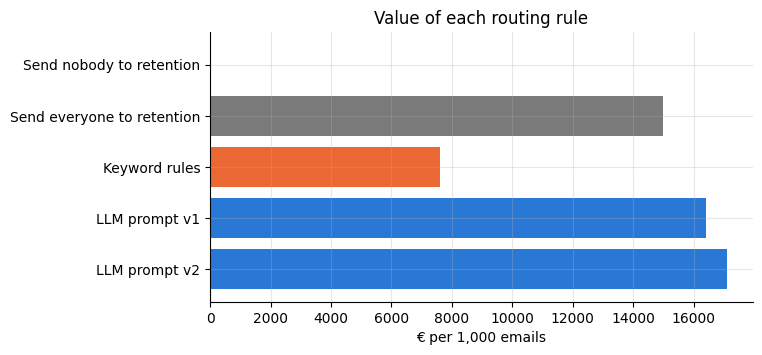

In [37]:
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = [GREY, GREY, ORANGE, BLUE, BLUE]
ax.barh(value.index, value.values, color=colors)
ax.set_xlabel("€ per 1,000 emails")
ax.set_title("Value of each routing rule")
ax.invert_yaxis()
plt.show()

## Exercise 5
1. "Send everyone to retention" looks good here. Why? (Hint: compare +€57 with −€3.) What would go wrong in real life if the retention team got **all** 10,000 emails a month?
2. In our sample, 9 of 30 emails (30%) are high risk; in a real inbox it might be 3%. Add a **capacity limit**: the retention team can handle only 3 in every 10 emails. Which rule would you choose now, and why?
3. Fill in the scoreboard slide from the lecture with your numbers.

In [38]:
CAPACITY = 0.3

rules = {"Send everyone to retention": everyone,
         "Keyword rules": pred_kw["churn_risk"],
         "LLM prompt v1": pred_v1["churn_risk"],
         "LLM prompt v2": pred_v2["churn_risk"]}

rows = []
for name, pred in rules.items():
    share_sent = (pred == "high").mean()
    handled = min(1, CAPACITY / share_sent) if share_sent > 0 else 0
    rows.append({"rule": name,
                 "share sent": f"{share_sent:.0%}",
                 "share the team can handle": f"{handled:.0%}",
                 "€ per 1,000 emails (with capacity)": round(euros_per_1000(pred) * handled)})
pd.DataFrame(rows).set_index("rule")

,share sent,share the team can handle,"€ per 1,000 emails (with capacity)"
rule,,,
Send everyone to retention,100%,30%,4500
Keyword rules,13%,100%,7600
LLM prompt v1,53%,56%,9225
LLM prompt v2,30%,100%,17100


# Part F — A chatbot with and without the company policy

A customer writes to the MegaTelCo chatbot. First, the bot answers **from its general knowledge only**. Then we give it MegaTelCo's real policy and a rule: *answer only from the policy*.

In [39]:
QUESTION = ("My father passed away last month. Can I get a refund for the months left on his "
            "contract? And can I still claim it after I return his router next month?")

POLICY = """MegaTelCo policy on the death of an account holder (version 2026-01):
1. A family member can close the account free of charge by showing a death certificate.
2. No early-termination fee is charged. Months left on the contract are cancelled, not refunded.
3. Any amount paid in advance for future months is refunded within 30 days of closing.
4. Rented equipment (routers, TV boxes) must be returned within 60 days; after that a 5,000 lek fee applies.
5. Requests must be made in a shop or by phone. They cannot be completed by chat or email."""

print(QUESTION)

My father passed away last month. Can I get a refund for the months left on his contract? And can I still claim it after I return his router next month?


In [40]:
answer_no_policy = ask_llm(
    "You are the customer-service chatbot of MegaTelCo, a telecom company. "
    "Answer the customer helpfully in 3-4 sentences.\n\nCustomer: " + QUESTION,
    want_json=False)
print(answer_no_policy)

I am so sorry for your loss. Yes, we can issue a pro-rated refund for the remaining months on the contract once the account is closed. You are welcome to claim the refund after you return the router next month, and our team will be happy to process everything for you then.


In [41]:
answer_with_policy = ask_llm(f"""You are the customer-service chatbot of MegaTelCo.
Answer ONLY using the policy below. If the policy does not answer something, say that a
colleague will contact the customer. Be kind and brief (3-4 sentences).

POLICY:
{POLICY}

Customer: {QUESTION}""", want_json=False)
print(answer_with_policy)

I am so sorry for your loss. Regarding the contract, months left on the contract are cancelled and not refunded. A colleague will contact the customer to assist you further with your request.


## Exercise 6
1. Compare the two answers with the policy, point by point. Did the first answer **promise** anything the policy does not allow (a refund of remaining months, a deadline, completing it by chat)?
2. Remember Air Canada: if the first answer were on MegaTelCo's website, who would pay for a wrong promise?
3. Which of the four controls from the lecture did we use in the second version? Which one is still missing before this goes live?

In [42]:
print("WITHOUT POLICY:\n", answer_no_policy, "\n")
print("WITH POLICY:\n", answer_with_policy)

WITHOUT POLICY:
 I am so sorry for your loss. Yes, we can issue a pro-rated refund for the remaining months on the contract once the account is closed. You are welcome to claim the refund after you return the router next month, and our team will be happy to process everything for you then. 

WITH POLICY:
 I am so sorry for your loss. Regarding the contract, months left on the contract are cancelled and not refunded. A colleague will contact the customer to assist you further with your request.


In [43]:
# A second LLM call can act as a first-pass reviewer: list every promise the policy does not support.
# (Useful for screening many answers, but a reviewer LLM can be wrong too: a person checks a sample.)
def check_against_policy(answer):
    raw = ask_llm(f"""You are a compliance reviewer at MegaTelCo.
Compare the chatbot ANSWER with the POLICY. List every statement or promise in the answer that the
policy does not support or that contradicts it. Answer with JSON:
{{"violations": ["...", "..."]}}  (an empty list if there are none)

POLICY:
{POLICY}

ANSWER:
{answer}""")
    try:
        return json.loads(raw).get("violations", [])
    except Exception:
        return ["(could not read the reviewer's answer)"]

for name, ans in [("Without policy", answer_no_policy), ("With policy", answer_with_policy)]:
    print(f"{name}:")
    for v in check_against_policy(ans) or ["no violations found"]:
        print("  -", v)

Without policy:
  - Months left on the contract are cancelled, not refunded.
  - Requests must be made in a shop or by phone. They cannot be completed by chat or email.
With policy:
  - A colleague will contact the customer to assist you further with your request contradicts the policy stating that requests must be made in a shop or by phone and cannot be completed by chat or email.
